Dataset shape: (150, 5)

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


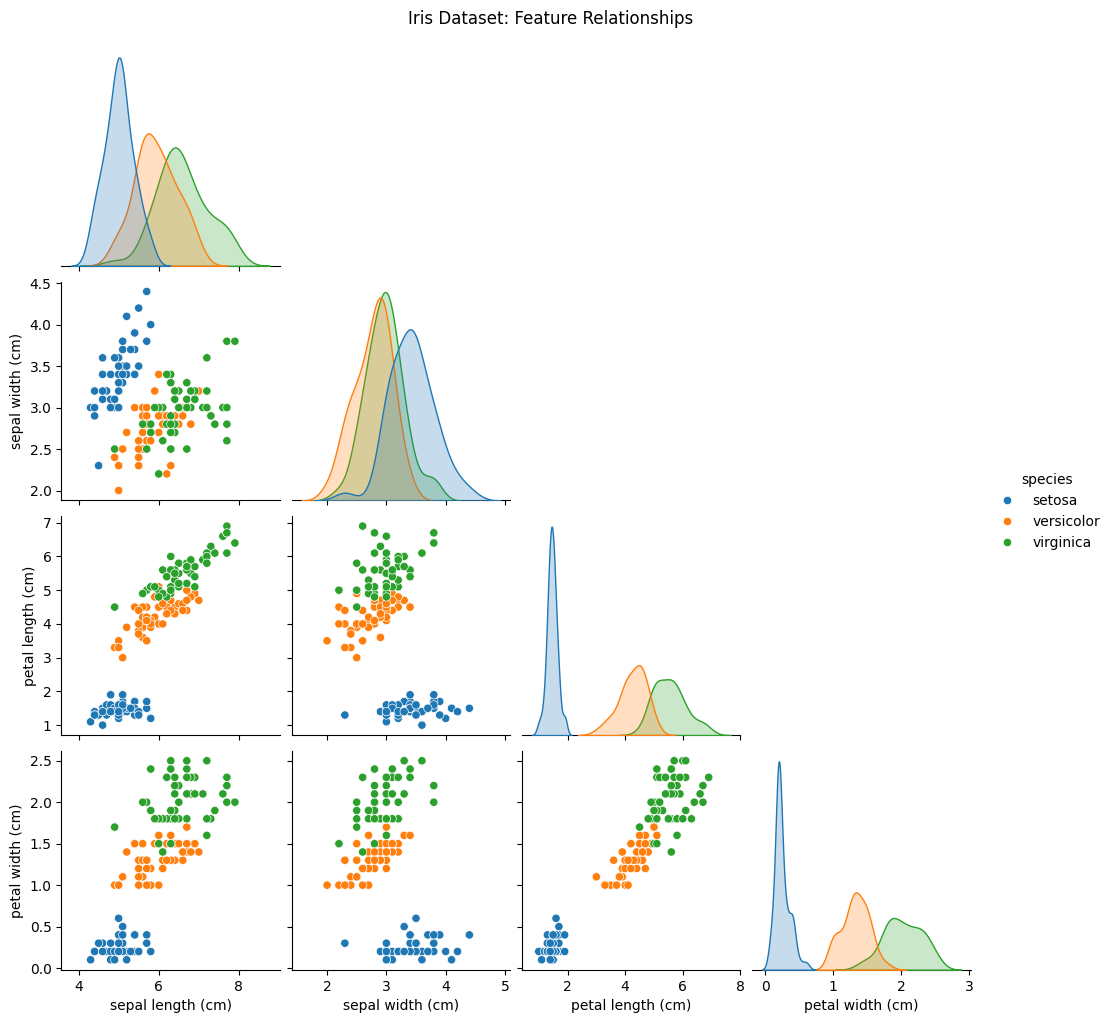

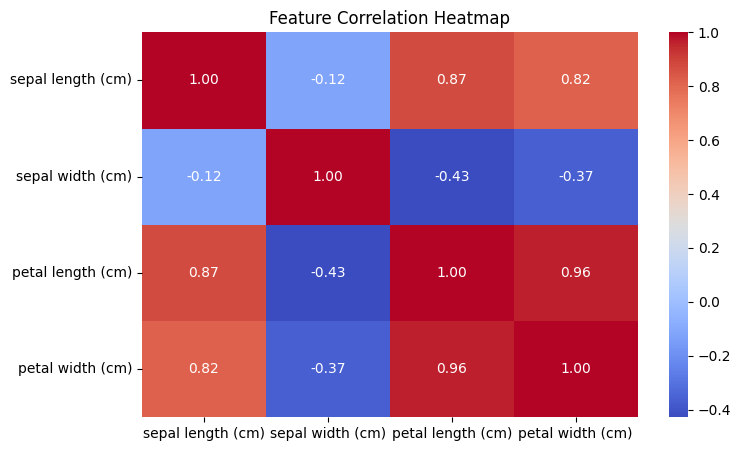


Training samples: 120
Testing samples: 30

Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



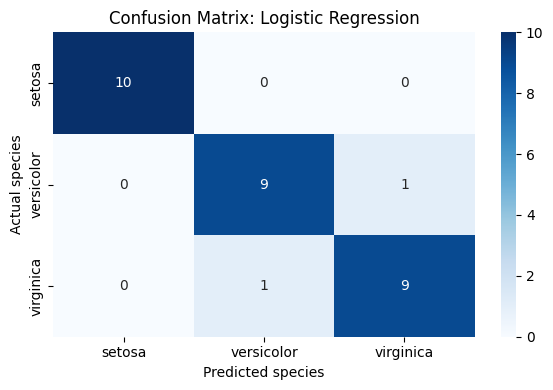


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



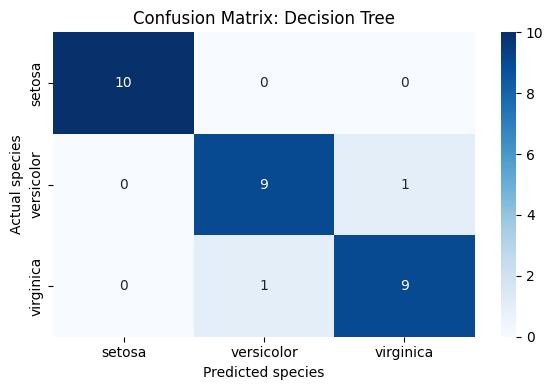


Model Comparison:
                     Accuracy  Precision (macro)  Recall (macro)  \
Logistic Regression     0.933              0.933           0.933   
Decision Tree           0.933              0.933           0.933   

                     F1-score (macro)  
Logistic Regression             0.933  
Decision Tree                   0.933  


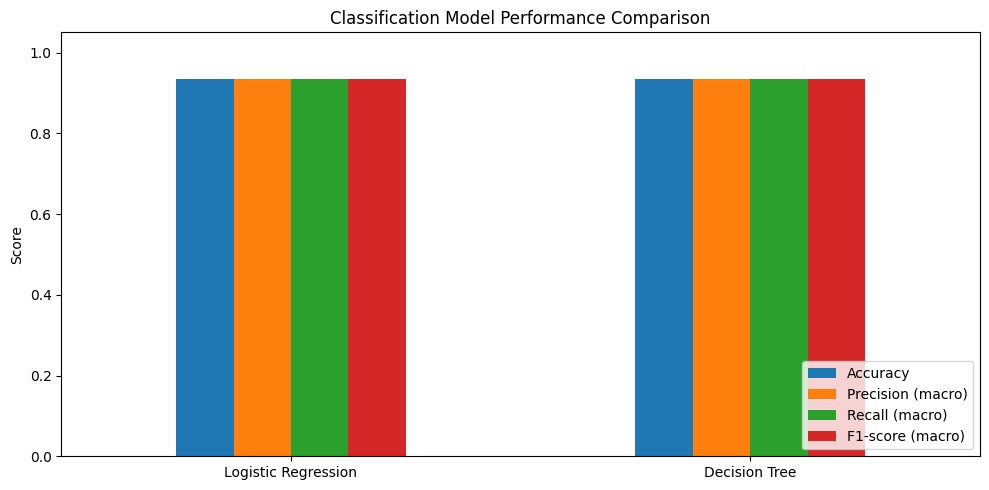

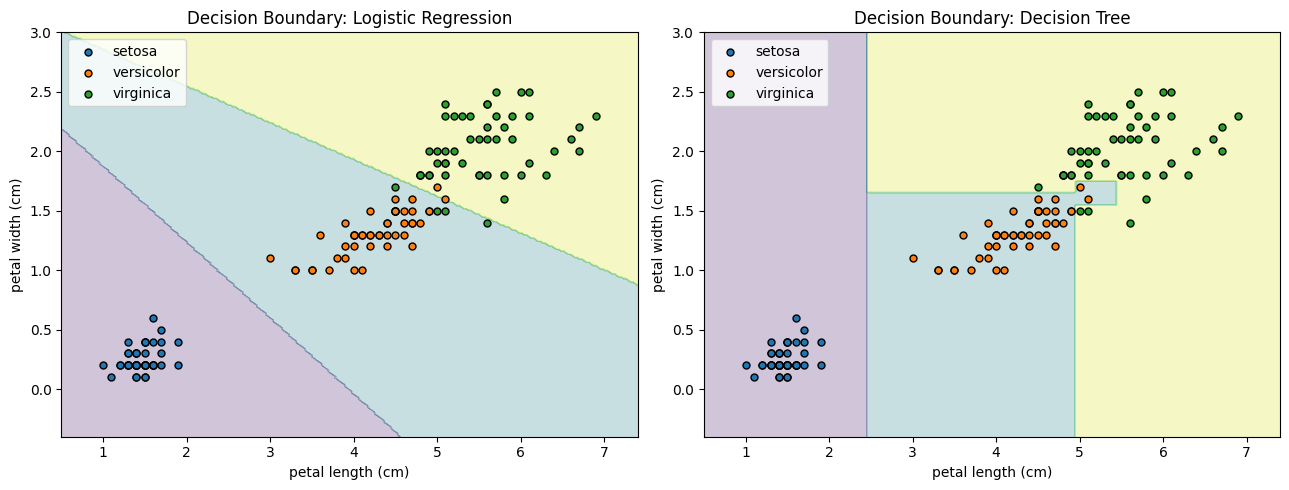


Project completed successfully.


In [1]:

# Multi-Class Benchmark Classification Pipeline
# Internship Task 1: Iris Dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Load the Iris dataset
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)
df = df.drop(columns="target")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nMissing values:")
print(df.isnull().sum())
print("\nClass distribution:")
print(df["species"].value_counts())

# 2. Exploratory data analysis
sns.pairplot(df, hue="species", corner=True)
plt.suptitle("Iris Dataset: Feature Relationships", y=1.02)
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(
    df.drop(columns="species").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

# 3. Separate features and target
X = df.drop(columns="species")
y = df["species"]

# 4. Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 5. Define models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(random_state=42))
    ])
}

# 6. Train models and calculate evaluation metrics
results = {}
class_names = list(iris.target_names)

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(
            y_test, predictions, average="macro",
            zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, predictions, average="macro",
            zero_division=0
        ),
        "F1-score (macro)": f1_score(
            y_test, predictions, average="macro",
            zero_division=0
        )
    }

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)
    print(classification_report(
        y_test, predictions,
        labels=class_names,
        zero_division=0
    ))

    # 7. Plot confusion matrix
    cm = confusion_matrix(
        y_test, predictions, labels=class_names
    )

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.xlabel("Predicted species")
    plt.ylabel("Actual species")
    plt.title(f"Confusion Matrix: {name}")
    plt.tight_layout()
    plt.show()

# 8. Compare both models
results_df = pd.DataFrame(results).T
print("\nModel Comparison:")
print(results_df.round(3))

results_df.plot(kind="bar", figsize=(10, 5))
plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 9. Decision-boundary visualizations
# Use two features for plotting only.
# The benchmark models above use all four features.

X_two = X.iloc[:, [2, 3]]
feature_names = list(X_two.columns)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model_class) in zip(
    axes,
    [
        ("Logistic Regression", LogisticRegression),
        ("Decision Tree", DecisionTreeClassifier)
    ]
):
    if name == "Logistic Regression":
        boundary_model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", model_class(max_iter=1000))
        ])
    else:
        boundary_model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", model_class(random_state=42))
        ])

    boundary_model.fit(X_two, y)

    x_min, x_max = X_two.iloc[:, 0].min() - 0.5, X_two.iloc[:, 0].max() + 0.5
    y_min, y_max = X_two.iloc[:, 1].min() - 0.5, X_two.iloc[:, 1].max() + 0.5

    import numpy as np

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = pd.DataFrame(
        np.c_[xx.ravel(), yy.ravel()],
        columns=feature_names
    )

    zz = boundary_model.predict(grid).reshape(xx.shape)
    class_to_num = {label: i for i, label in enumerate(class_names)}
    zz_num = np.vectorize(class_to_num.get)(zz)

    ax.contourf(
        xx, yy, zz_num,
        alpha=0.25, cmap="viridis"
    )

    for species in class_names:
        mask = y == species
        ax.scatter(
            X_two.loc[mask, feature_names[0]],
            X_two.loc[mask, feature_names[1]],
            label=species, edgecolor="black", s=25
        )

    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])
    ax.set_title(f"Decision Boundary: {name}")
    ax.legend()

plt.tight_layout()
plt.show()

print("\nProject completed successfully.")
